# Relatório de modelagem — detecção de manipulação da malha de controle

**Projeto Integrado em Ciência de Dados — Módulo 3**  
PPGMCS/UNIMONTES · Prof.ª Luciana Balieiro Cosme  
Aluno: **Samuel Rodrigues Gonçalves**  
Outubro de 2026

---

Este caderno continua o relatório de EDA (`01_eda.ipynb`) e entrega as cinco seções pedidas:
**baseline**, **experimentos**, **modelo final**, **análise de erros** e **limitações**.

**O que estou tentando fazer.** Acusar, em até um minuto, que alguém mexeu na malha de
controle de um sistema industrial — mudou um setpoint, um comando de válvula ou o parâmetro
interno de um algoritmo do controlador — mantendo as variáveis dentro da faixa operacional,
de modo que nenhum alarme convencional dispara.

**Como eu meço sucesso.** Não por acurácia: responder sempre "normal" acerta 94% das janelas
e não detecta nada. A métrica primária é a **cobertura de eventos sob orçamento de alarme** —
quantos dos ataques rotulados o detector acusa, com no máximo **1 alarme falso por hora** e
**2% do tempo normal sob alarme**. As métricas pedidas na disciplina (recall e F1 da classe
minoritária, AUC-ROC, matriz de confusão) são reportadas também, na seção 3.

**Três regras que valem para o caderno inteiro.**

1. O corte treino/teste é **cronológico**, nunca aleatório: em série temporal, embaralhar é vazamento.
2. **Nada é ajustado no teste.** Hiperparâmetros saem de `TimeSeriesSplit` dentro do treino;
   o limiar de alarme sai de um trecho de validação anterior ao teste; o teste aparece **uma única vez**,
   na seção 3.
3. `random_state=42` em tudo.

In [1]:
import sys, json, pickle, warnings
from pathlib import Path
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
SEMENTE = 42
np.random.seed(SEMENTE)

RAIZ = Path.cwd()
while not (RAIZ / 'src').is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
FIGS = RAIZ / 'reports' / 'figures'; FIGS.mkdir(parents=True, exist_ok=True)

from src import data_loading as dl
from src import preprocess as pp
from src import avaliacao as av

print(f'pacotes carregados · semente {SEMENTE} · {len(list(RAIZ.glob("src/*.py")))} módulos em src/')

pacotes carregados · semente 42 · 6 módulos em src/


In [2]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

S1, S2, S3, S8 = '#2a78d6', '#eb6834', '#2f9e74', '#e34948'
SURF, TXT, TXT2, GRID, NEU = '#fcfcfb', '#0b0b0b', '#52514e', '#e3e2df', '#c8ccd1'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': GRID,
    'axes.labelcolor': TXT2, 'text.color': TXT, 'xtick.color': TXT2, 'ytick.color': TXT2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'figure.dpi': 130})

def titulo(fig, t, s):
    fig.text(.005, 1.13, t, ha='left', fontsize=12.5, fontweight='bold', color=TXT)
    fig.text(.005, 1.03, s, ha='left', fontsize=9.5, color=TXT2)

CORES = {'boosting': S1, 'logistica': S2, 'iforest': S3, 'limite_fixo': NEU, 'dummy': '#9aa0a6'}
NOMES = {'boosting': 'gradient boosting', 'logistica': 'regressão logística',
         'iforest': 'isolation forest', 'limite_fixo': 'alarme por limite fixo',
         'dummy': 'baseline trivial'}

Matplotlib is building the font cache; this may take a moment.


## 0. Dados, pré-processamento e os três trechos do tempo

Os dois arquivos com ataque do HAI 23.05 (`hai-test1`, 12–13/08/2022; `hai-test2`, 17–19/08/2022)
somam **284.400 segundos = 79 h** e **52 ataques rotulados**. O pré-processamento é exatamente
o do M2, aplicado por `src/preprocess.py`: remoção das 18 tags sem variância, tratamento dos
valores fisicamente impossíveis, tratamento das redundâncias (incluindo a substituição dos pares
comando/realimentação pelo **resíduo**) e a flag de desvio do repouso de `P1_PCV02D`. Resultado:
**64 variáveis**.

In [3]:
X_bruto, y = dl.carregar_rotulado()
X = pp.preparar(X_bruto)
print(f'{len(X):,} segundos · {X.shape[1]} variáveis · {y.mean()*100:.2f}% rotulados como ataque'.replace(',', '.'))
eventos_todos = av.eventos(y)
print(f'{len(eventos_todos)} ataques; duração mediana {np.median([b-a+1 for a, b in eventos_todos]):.0f} s')

284.400 segundos · 64 variáveis · 4.00% rotulados como ataque
52 ataques; duração mediana 132 s


### O corte do tempo

Três trechos consecutivos, nessa ordem — e essa é a decisão que torna todo o resto honesto:

| trecho | segundos | duração | eventos | para que serve |
|---|---|---|---|---|
| **treino** | 0 – 144.180 | 40,0 h | 33 | ajustar modelos e hiperparâmetros |
| **validação** | 144.180 – 192.240 | 13,4 h | 1 | calibrar **o limiar de alarme** |
| **teste** | 192.240 – 284.400 | 25,6 h | 18 | uma única medição final |

O trecho de validação tem **um** evento de propósito: ele não serve para medir detecção, serve
para medir **custo de alarme falso**, e para isso o que importa é ter bastante tempo normal.
A escolha entre modelos, que precisa de eventos, é feita de outro jeito — fora-da-amostra
dentro do treino (seção 2.3).

Janelas que cruzam uma fronteira são descartadas: nenhuma amostra contém dados dos dois lados.

In [4]:
CORTE_TREINO, CORTE_TESTE = 144180, 192240
N_SEG = len(X)

def montar(tamanho):
    F, rot = pp.janelas(X, y, tamanho=tamanho, passo=tamanho // 2, corte=CORTE_TESTE)
    ini = F['inicio_seg'].to_numpy()
    Xw = F.drop(columns=['inicio_seg'])
    m_tr = (ini + tamanho) <= CORTE_TREINO
    m_va = (ini >= CORTE_TREINO) & (ini + tamanho <= CORTE_TESTE)
    m_te = ini >= CORTE_TESTE
    return dict(X=Xw, y=rot.to_numpy().astype('int8'), ini=ini, tr=m_tr, va=m_va, te=m_te, tam=tamanho)

JANELAS = {t: montar(t) for t in (30, 60, 120)}
for t, J in JANELAS.items():
    print(f'janela {t:3d} s · passo {t//2:3d} s · {len(J["X"]):6,} janelas · {J["X"].shape[1]} features · '
          f'treino {J["tr"].sum():5,} ({J["y"][J["tr"]].mean()*100:.2f}% ataque) · '
          f'teste {J["te"].sum():5,} ({J["y"][J["te"]].mean()*100:.2f}% ataque)'.replace(',', '.'))

janela  30 s · passo  15 s · 18.958 janelas · 192 features · treino 9.611 (5.19% ataque) · teste 6.143 (5.47% ataque)
janela  60 s · passo  30 s ·  9.478 janelas · 192 features · treino 4.805 (5.74% ataque) · teste 3.071 (6.02% ataque)
janela 120 s · passo  60 s ·  4.738 janelas · 192 features · treino 2.402 (6.91% ataque) · teste 1.535 (7.04% ataque)


Cada janela vira três estatísticas por variável — **média**, **desvio-padrão móvel** e
**delta** (último menos primeiro segundo) — dando 64 × 3 = **192 features**. A janela é rotulada
como ataque se **qualquer** segundo dela for ataque.

O desvio-padrão móvel está aí por uma razão de domínio: a manipulação que me interessa
quase não muda o **nível** da variável (foi assim que ela escapou dos alarmes), mas muda a
**agitação** do comando enquanto o controlador tenta corrigir o que o atacante desloca.

---

## 1. Baseline — o piso

Sem piso não há progresso. Três pisos, do mais trivial ao mais realista:

1. **Baseline trivial** (`DummyClassifier`): responde sempre a classe majoritária.
2. **Alarme por limite fixo**: a regra que a planta de verdade já tem. Conta quantas das 192
   features saem da faixa p0,5–p99,5 observada na **operação normal do treino**. Sem aprendizado.
3. **Resíduo comando/realimentação com limiar p99**, medido no M1: detectou **1 de 14** eventos
   do `hai-test1` a 1% de alarme falso. É o piso que motivou o projeto.

Os dois primeiros entram no caderno como experimentos rastreados; o terceiro está no relatório do M1.

In [5]:
from sklearn.dummy import DummyClassifier

J = JANELAS[60]
Xtr, ytr = J['X'][J['tr']], J['y'][J['tr']]

dummy = DummyClassifier(strategy='prior', random_state=SEMENTE).fit(Xtr, ytr)
acuracia = (dummy.predict(J['X'][J['te']]) == J['y'][J['te']]).mean()
print(f'baseline trivial · acurácia no teste = {acuracia*100:.2f}% · ataques detectados = 0')
print('é exatamente por isso que acurácia não é métrica deste projeto.')

baseline trivial · acurácia no teste = 93.98% · ataques detectados = 0
é exatamente por isso que acurácia não é métrica deste projeto.


In [6]:
def escore_limite_fixo(Xtreino, ytreino, blocos):
    """Regra convencional: conta features fora da faixa vista na operação normal."""
    normal = Xtreino.loc[ytreino == 0]
    lo, hi = normal.quantile(0.005), normal.quantile(0.995)
    return [((B < lo) | (B > hi)).sum(axis=1).to_numpy(float) for B in blocos]

s_va_lf, s_te_lf = escore_limite_fixo(Xtr, ytr, [J['X'][J['va']], J['X'][J['te']]])
print('escore do alarme por limite fixo pronto (nº de features fora de faixa por janela)')

escore do alarme por limite fixo pronto (nº de features fora de faixa por janela)


### Como o limiar de alarme é escolhido

Todo escore vira alarme por um limiar. Escolher esse limiar olhando o teste seria escolher
a resposta. Então ele é calibrado no **trecho de validação**, pela regra:

> o limiar mais permissivo que ainda respeita **≤ 1 bloco de alarme falso por hora** e
> **≤ 2% do tempo normal sob alarme**.

A segunda restrição não é decoração. Sem ela, um detector que acusa o tempo todo registraria
"zero alarmes falsos" — um único bloco contínuo que encosta em todos os ataques — e passaria
no orçamento. É o alarme permanente que a sala de controle aprende a ignorar.

A implementação está em `src/avaliacao.py` (`calibrar_limiar`, `metricas_evento`).

---

## 2. Experimentos

Quatro abordagens, acima do mínimo de três, cobrindo as três famílias que a disciplina pede
(trivial, linear, não-linear) mais uma não supervisionada que faz sentido no domínio:

| abordagem | família | por que está aqui |
|---|---|---|
| `DummyClassifier` | trivial | define o piso |
| alarme por limite fixo | regra, sem aprendizado | é o que a planta já tem |
| **regressão logística** (`class_weight='balanced'`) | linear | o simples que precisa ser batido |
| **gradient boosting** (`HistGradientBoostingClassifier`) | não-linear | só se justifica se superar o linear |
| **Isolation Forest** | não supervisionada | treina **só com operação normal** — serve para ataque nunca visto |

Hiperparâmetros por `RandomizedSearchCV` com `TimeSeriesSplit(5)`, otimizando **PR-AUC**
(`average_precision`), que é a métrica apropriada com 4% de positivos.

### 2.1 Divergência declarada: `TimeSeriesSplit` no lugar de `StratifiedKFold`

O checklist da disciplina pede `train_test_split(stratify=y)` e `StratifiedKFold(5)`. **Não uso
nenhum dos dois, de propósito.** Ambos embaralham o tempo. Janelas vizinhas compartilham segundos;
se uma cai no treino e a outra na validação, o modelo está sendo avaliado em dados que praticamente
já viu — a avaliação sobe e o número não significa nada. O equivalente alinhado ao espírito da regra
(treinar no passado, avaliar no futuro) é `TimeSeriesSplit`.

Pela mesma razão **não uso SMOTE**: ele interpola entre janelas temporalmente adjacentes, o que é
vazamento disfarçado de balanceamento. O desbalanceamento é tratado com `class_weight='balanced'`.

In [7]:
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

CV = TimeSeriesSplit(5)

ESPACO = {
    'logistica': (Pipeline([('esc', StandardScaler()),
                            ('clf', LogisticRegression(class_weight='balanced', solver='lbfgs',
                                                       max_iter=4000, random_state=SEMENTE))]),
                  {'clf__C': np.logspace(-4, 2, 25)}, 25),
    'boosting': (HistGradientBoostingClassifier(class_weight='balanced', random_state=SEMENTE,
                                                early_stopping=False),
                 {'max_iter': [100, 200, 300, 400], 'learning_rate': [0.03, 0.06, 0.1, 0.2],
                  'max_leaf_nodes': [15, 31, 63], 'min_samples_leaf': [10, 20, 40],
                  'l2_regularization': [0.0, 0.1, 1.0]}, 20),
}

busca = {}
for tam, Jt in JANELAS.items():
    Xa, ya = Jt['X'][Jt['tr']], Jt['y'][Jt['tr']]
    for nome, (est, grade, n_iter) in ESPACO.items():
        b = RandomizedSearchCV(est, grade, n_iter=n_iter, cv=CV, scoring='average_precision',
                               random_state=SEMENTE, n_jobs=-1).fit(Xa, ya)
        busca[(nome, tam)] = b
        print(f'{nome:10s} janela {tam:3d} s · PR-AUC CV = {b.best_score_:.3f} · {b.best_params_}')

logistica  janela  30 s · PR-AUC CV = 0.317 · {'clf__C': np.float64(0.01778279410038923)}


boosting   janela  30 s · PR-AUC CV = 0.274 · {'min_samples_leaf': 10, 'max_leaf_nodes': 15, 'max_iter': 100, 'learning_rate': 0.1, 'l2_regularization': 0.0}


logistica  janela  60 s · PR-AUC CV = 0.328 · {'clf__C': np.float64(0.005623413251903491)}


boosting   janela  60 s · PR-AUC CV = 0.236 · {'min_samples_leaf': 40, 'max_leaf_nodes': 15, 'max_iter': 400, 'learning_rate': 0.03, 'l2_regularization': 0.1}


logistica  janela 120 s · PR-AUC CV = 0.382 · {'clf__C': np.float64(0.1)}


boosting   janela 120 s · PR-AUC CV = 0.260 · {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0.1}


### 2.2 Métricas por ponto na validação cruzada

Primeiro as métricas que a disciplina pede, medidas em `TimeSeriesSplit(5)` **dentro do treino**
— média ± desvio das 5 dobras.

In [8]:
modelos_cv = {
    'dummy': DummyClassifier(strategy='prior', random_state=SEMENTE),
    'logistica': busca[('logistica', 60)].best_estimator_,
    'boosting': busca[('boosting', 60)].best_estimator_,
}
linhas = []
for nome, est in modelos_cv.items():
    s = cross_validate(est, Xtr, ytr, cv=CV, scoring=['f1', 'average_precision', 'roc_auc'])
    linhas.append({'abordagem': NOMES[nome],
                   'F1 da classe ataque': f"{s['test_f1'].mean():.3f} ± {s['test_f1'].std():.3f}",
                   'PR-AUC': f"{s['test_average_precision'].mean():.3f} ± {s['test_average_precision'].std():.3f}",
                   'AUC-ROC': f"{s['test_roc_auc'].mean():.3f} ± {s['test_roc_auc'].std():.3f}"})
cv_tab = pd.DataFrame(linhas).set_index('abordagem')
cv_tab

,F1 da classe ataque,PR-AUC,AUC-ROC
abordagem,,,
baseline trivial,0.000 ± 0.000,0.057 ± 0.008,0.500 ± 0.000
regressão logística,0.303 ± 0.151,0.328 ± 0.167,0.741 ± 0.141
gradient boosting,0.211 ± 0.174,0.236 ± 0.137,0.693 ± 0.125


A regressão logística **supera o gradient boosting** em todas as três métricas da validação
cruzada, com desvio menor. Esse é o primeiro sinal de que o modelo complexo não se justifica aqui —
e é exatamente o degrau que a disciplina manda verificar antes de avançar.

Mas F1 por ponto não é a métrica do projeto. Um ataque de 132 s acusado no segundo 10 e outro
acusado no segundo 125 valem o mesmo para o F1; não valem o mesmo para a operação. A escolha
precisa ser feita pela métrica primária — e sem tocar no teste.

### 2.3 Seleção pela métrica primária, fora-da-amostra, dentro do treino

A métrica primária não cabe no trecho de validação (um evento só). A saída é calculá-la
**fora-da-amostra dentro do treino**: em cada dobra do `TimeSeriesSplit(5)`, ajusto no passado,
calibro o limiar na **primeira metade** do trecho de validação da dobra e **meço a cobertura na
segunda metade**. Isso dá 14 eventos medidos fora-da-amostra, sem que o teste seja tocado.

É assim que o modelo final e o tamanho de janela são escolhidos.

In [9]:
def escore_fora_amostra(nome, Xa, ya, Xb, tam):
    if nome == 'dummy':
        return DummyClassifier(strategy='prior', random_state=SEMENTE).fit(Xa, ya).predict_proba(Xb)[:, 1]
    if nome == 'limite_fixo':
        return escore_limite_fixo(Xa, ya, [Xb])[0]
    if nome == 'iforest':
        m = IsolationForest(n_estimators=400, random_state=SEMENTE, n_jobs=-1).fit(Xa.loc[ya == 0])
        return -m.score_samples(Xb)
    from sklearn.base import clone
    return clone(busca[(nome, tam)].best_estimator_).fit(Xa, ya).predict_proba(Xb)[:, 1]


def cobertura_oof(nome, tam, orcamento=1.0):
    Jt = JANELAS[tam]
    Xa = Jt['X'][Jt['tr']].reset_index(drop=True)
    ya, ia_todos = Jt['y'][Jt['tr']], Jt['ini'][Jt['tr']]
    det = ev = 0
    falsos = []
    for tr_i, va_i in CV.split(Xa):
        s = escore_fora_amostra(nome, Xa.iloc[tr_i], ya[tr_i], Xa.iloc[va_i], tam)
        meio = len(va_i) // 2
        a_cal, b_cal = int(ia_todos[va_i[0]]), int(ia_todos[va_i[meio]])
        b_med = int(ia_todos[va_i[-1]]) + tam
        lim = av.calibrar_limiar(s[:meio], ia_todos[va_i[:meio]], y.to_numpy(), a_cal, b_cal, tam,
                                 orcamento_hora=orcamento, orcamento_tempo=0.02 * orcamento, n_grade=120)
        flag = av.janelas_para_segundos(ia_todos[va_i[meio:]], s[meio:] >= lim, tam, N_SEG)
        m = av.metricas_evento(flag, y.to_numpy(), b_cal, b_med)
        det += m['detectados']; ev += m['eventos']; falsos.append(m['falsos_por_hora'])
    return {'abordagem': nome, 'janela': tam, 'detectados': det, 'eventos': ev,
            'cobertura': det / ev, 'falsos_por_hora': float(np.mean(falsos))}


selecao = [cobertura_oof(n, t) for t in (30, 60, 120) for n in ('logistica', 'boosting')]
selecao += [cobertura_oof(n, 60) for n in ('dummy', 'limite_fixo', 'iforest')]
selecao = pd.DataFrame(selecao).sort_values('cobertura', ascending=False)
selecao.assign(cobertura=lambda d: (d.cobertura * 100).round(1)).reset_index(drop=True)

,abordagem,janela,detectados,eventos,cobertura,falsos_por_hora
0,logistica,30,8,14,57.1,1.376559
1,logistica,60,8,14,57.1,0.239401
2,boosting,30,6,14,42.9,0.538653
3,limite_fixo,60,6,14,42.9,1.556110
4,boosting,120,5,14,35.7,0.238806
5,iforest,60,5,14,35.7,1.197007
6,boosting,60,4,14,28.6,0.179551
7,logistica,120,4,14,28.6,0.059701
8,dummy,60,0,14,0.0,0.000000


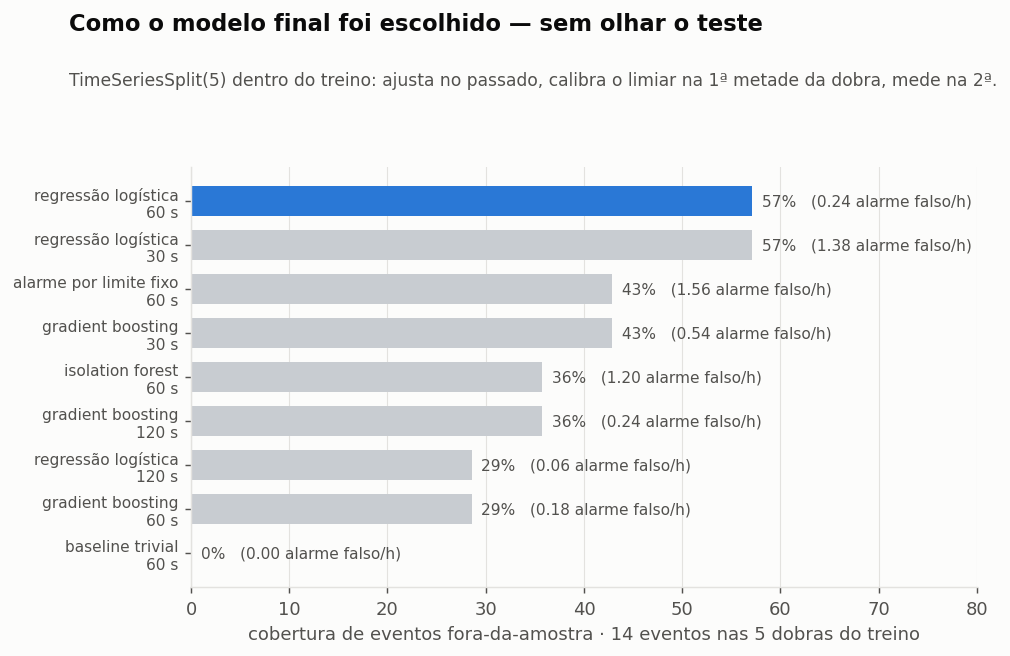

In [10]:
sel = selecao.sort_values('cobertura')
fig, ax = plt.subplots(figsize=(7.8, 4.2))
cor = [S1 if (m == 'logistica' and j == 60) else NEU for m, j in zip(sel.abordagem, sel.janela)]
ax.barh(range(len(sel)), sel.cobertura * 100, color=cor, height=.68)
ax.set_yticks(range(len(sel)))
ax.set_yticklabels([f'{NOMES[m]}\n{j} s' for m, j in zip(sel.abordagem, sel.janela)], fontsize=8.5)
for i, (c, f) in enumerate(zip(sel.cobertura, sel.falsos_por_hora)):
    ax.text(c * 100 + 1, i, f'{c*100:.0f}%   ({f:.2f} alarme falso/h)', va='center', fontsize=8.5, color=TXT2)
ax.set_xlabel('cobertura de eventos fora-da-amostra · 14 eventos nas 5 dobras do treino')
ax.set_xlim(0, 80); ax.grid(axis='y', visible=False); ax.set_axisbelow(True)
titulo(fig, 'Como o modelo final foi escolhido — sem olhar o teste',
       'TimeSeriesSplit(5) dentro do treino: ajusta no passado, calibra o limiar na 1ª metade da dobra, mede na 2ª.')
fig.savefig(FIGS / 'g8_selecao.png', bbox_inches='tight'); plt.show()

**Decisão.** A regressão logística cobre 8 dos 14 eventos fora-da-amostra (57%) nas janelas de
30 s e de 60 s; o gradient boosting fica entre 29% e 43%, em qualquer janela. O empate entre 30 s e 60 s
é desempatado pelo custo: **1,38 alarme falso/hora contra 0,24**.

**Modelo final: regressão logística com `class_weight='balanced'`, janela de 60 s, passo de 30 s.**

Essa escolha é coerente com as três evidências disponíveis dentro do treino — F1 em CV, PR-AUC em CV
e cobertura fora-da-amostra — e com a regra da disciplina: o modelo complexo só se justifica se
superar o simples, e aqui ele não supera. A janela de 60 s também é a que faz sentido no domínio:
é metade da duração mediana dos ataques (132 s), então pelo menos uma janela inteira cabe dentro
de um ataque típico.

---

## 3. Modelo final e avaliação no teste

**Escolha:** regressão logística, `class_weight='balanced'`, `StandardScaler` dentro do `Pipeline`,
`C` ajustado por `RandomizedSearchCV`, janela de 60 s.

**Justificativa:** melhor cobertura fora-da-amostra (57%) ao menor custo de alarme (0,24/h); melhor
F1 e PR-AUC em validação cruzada; é o modelo mais simples entre os que atingem esse resultado; e
seus coeficientes são auditáveis — em segurança operacional, poder explicar por que um alarme
disparou vale tanto quanto disparar.

**Nota sobre o `StandardScaler`.** O M2 decidiu `RobustScaler` para o ramo linear, porque entre as
tags brutas havia outliers que eram sinal. Na camada de janelas o objeto mudou: **34 das 192 features
têm IQR igual a zero** (desvio e delta de tags quase binárias), o que deixa a matriz mal condicionada.
Medido em CV, o `RobustScaler` entrega PR-AUC 0,205 contra **0,284** do `StandardScaler`, e demora
40× mais para ajustar. A decisão do M2 continua valendo para as tags brutas; na camada de janelas
ela foi revista com esse número na mão.

**A partir daqui o conjunto de teste é usado — uma única vez.**

In [11]:
final = busca[('logistica', 60)].best_estimator_
print('hiperparâmetros do modelo final:', busca[('logistica', 60)].best_params_)

escores = {}
escores['logistica'] = (final.predict_proba(J['X'][J['va']])[:, 1], final.predict_proba(J['X'][J['te']])[:, 1])
bo = busca[('boosting', 60)].best_estimator_
escores['boosting'] = (bo.predict_proba(J['X'][J['va']])[:, 1], bo.predict_proba(J['X'][J['te']])[:, 1])
io = IsolationForest(n_estimators=400, random_state=SEMENTE, n_jobs=-1).fit(Xtr.loc[ytr == 0])
escores['iforest'] = (-io.score_samples(J['X'][J['va']]), -io.score_samples(J['X'][J['te']]))
escores['limite_fixo'] = (s_va_lf, s_te_lf)
escores['dummy'] = (dummy.predict_proba(J['X'][J['va']])[:, 1], dummy.predict_proba(J['X'][J['te']])[:, 1])

y_np = y.to_numpy()
limiar, resultado = {}, {}
for nome, (s_va, s_te) in escores.items():
    limiar[nome] = av.calibrar_limiar(s_va, J['ini'][J['va']], y_np, CORTE_TREINO, CORTE_TESTE, 60,
                                      orcamento_hora=1.0, orcamento_tempo=0.02, n_grade=120)
    flag = av.janelas_para_segundos(J['ini'][J['te']], s_te >= limiar[nome], 60, N_SEG)
    resultado[nome] = {'flag': flag,
                       'evento': av.metricas_evento(flag, y_np, CORTE_TESTE, N_SEG),
                       'ponto': av.metricas_ponto(J['y'][J['te']], (s_te >= limiar[nome]).astype(int), s_te)}

pd.DataFrame([{'abordagem': NOMES[n],
               'eventos detectados': f"{r['evento']['detectados']}/{r['evento']['eventos']}",
               'cobertura': f"{r['evento']['cobertura']*100:.1f}%",
               'alarmes falsos/h': round(r['evento']['falsos_por_hora'], 2),
               '% do tempo normal em alarme': round(r['evento']['fracao_normal_em_alarme'] * 100, 2),
               'latência mediana (s)': r['evento']['latencia_mediana'],
               'recall (ponto)': round(r['ponto']['recall_1'], 3),
               'F1 (ponto)': round(r['ponto']['f1_1'], 3),
               'AUC-ROC': round(r['ponto'].get('auc_roc', float('nan')), 3),
               'PR-AUC': round(r['ponto'].get('pr_auc', float('nan')), 3)}
              for n, r in resultado.items()]).set_index('abordagem')

hiperparâmetros do modelo final: {'clf__C': np.float64(0.005623413251903491)}


,eventos detectados,cobertura,alarmes falsos/h,% do tempo normal em alarme,latência mediana (s),recall (ponto),F1 (ponto),AUC-ROC,PR-AUC
abordagem,,,,,,,,,
regressão logística,8/18,44.4%,0.43,1.87,0.0,0.465,0.564,0.762,0.521
gradient boosting,10/18,55.6%,0.94,3.28,0.0,0.492,0.543,0.823,0.490
isolation forest,8/18,44.4%,1.29,3.85,12.5,0.454,0.501,0.728,0.434
alarme por limite fixo,7/18,38.9%,1.09,3.20,25.0,0.476,0.537,0.822,0.515
baseline trivial,0/18,0.0%,0.00,0.00,NaN,0.000,0.000,0.500,0.060


In [12]:
from sklearn.metrics import classification_report
s_te_final = escores['logistica'][1]
pred_final = (s_te_final >= limiar['logistica']).astype(int)
print(classification_report(J['y'][J['te']], pred_final, target_names=['normal', 'ataque'], digits=3))

              precision    recall  f1-score   support

      normal      0.966     0.988     0.977      2886
      ataque      0.717     0.465     0.564       185

    accuracy                          0.957      3071
   macro avg      0.842     0.727     0.771      3071
weighted avg      0.951     0.957     0.952      3071



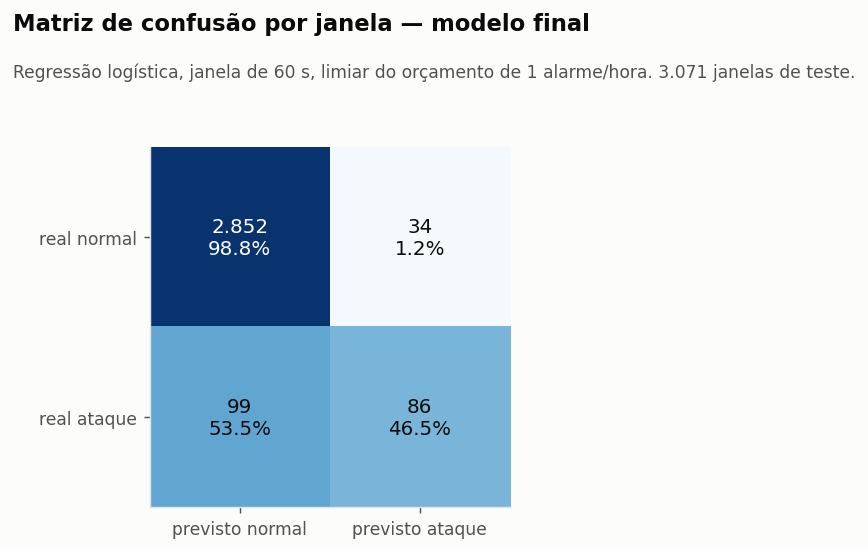

In [13]:
pt = resultado['logistica']['ponto']
cm = np.array([[pt['vn'], pt['fp']], [pt['fn'], pt['vp']]])
fig, ax = plt.subplots(figsize=(4.8, 3.6))
ax.imshow(cm / cm.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
for i in range(2):
    for j2 in range(2):
        p = cm[i, j2] / cm[i].sum() * 100
        ax.text(j2, i, f'{cm[i, j2]:,}\n{p:.1f}%'.replace(',', '.'), ha='center', va='center',
                fontsize=11, color='white' if p > 55 else TXT)
ax.set_xticks([0, 1]); ax.set_xticklabels(['previsto normal', 'previsto ataque'], fontsize=9.5)
ax.set_yticks([0, 1]); ax.set_yticklabels(['real normal', 'real ataque'], fontsize=9.5)
ax.grid(False)
titulo(fig, 'Matriz de confusão por janela — modelo final',
       'Regressão logística, janela de 60 s, limiar do orçamento de 1 alarme/hora. 3.071 janelas de teste.')
fig.savefig(FIGS / 'g4_confusao.png', bbox_inches='tight'); plt.show()

**O custo de cada erro, em termos da operação — que é o que a matriz precisa dizer.**

- **34 falsos positivos** (1,2% das janelas normais): o operador vai conferir um alarme que não
  era nada. Agrupados, dão 0,43 alarme por hora — um a cada duas horas e meia, custo que a sala absorve.
- **99 falsos negativos** (53,5% das janelas de ataque): *por janela* parece catastrófico, mas por
  **evento** não é a mesma coisa — basta uma janela acusada para o ataque ser detectado. Essas 99
  janelas perdidas se concentram em ataques que escapam **inteiros** (seção 4), e não em ataques
  detectados tarde.
- Os dois erros não têm o mesmo preço. Um falso positivo custa alguns minutos de um operador; um
  falso negativo custa um atacante com acesso ao controle do processo por tempo indeterminado.
  Por isso o limiar foi calibrado por **orçamento de alarme**, e não maximizando F1.

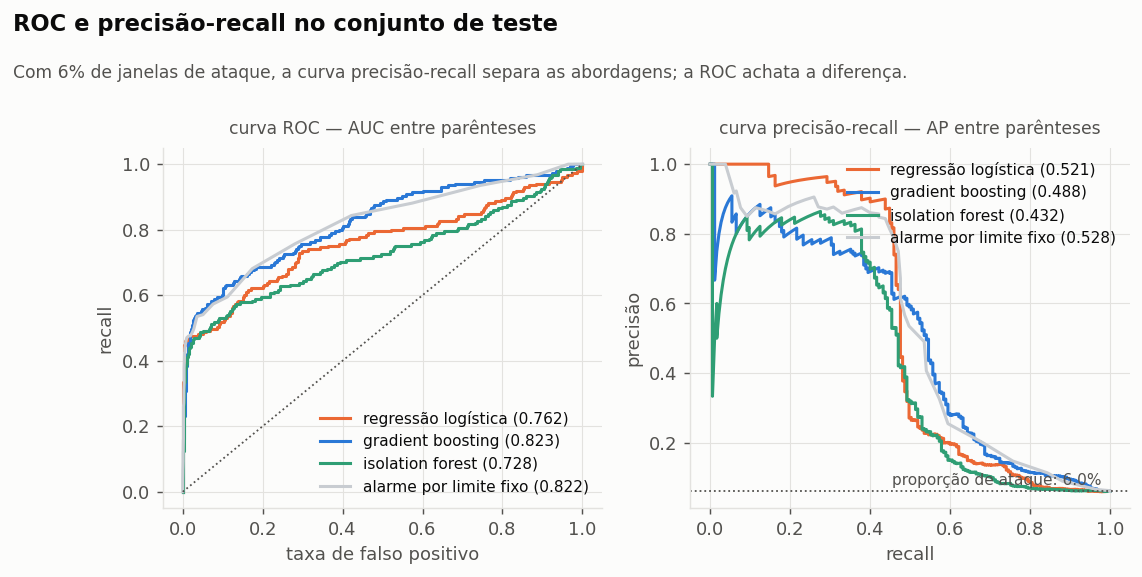

In [14]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))
for nome in ['logistica', 'boosting', 'iforest', 'limite_fixo']:
    sc = escores[nome][1]
    fpr, tpr, _ = roc_curve(J['y'][J['te']], sc)
    axes[0].plot(fpr, tpr, color=CORES[nome], lw=1.7, label=f'{NOMES[nome]} ({auc(fpr, tpr):.3f})')
    pr, rc, _ = precision_recall_curve(J['y'][J['te']], sc)
    axes[1].plot(rc, pr, color=CORES[nome], lw=1.7, label=f'{NOMES[nome]} ({auc(rc, pr):.3f})')
axes[0].plot([0, 1], [0, 1], ls=':', color=TXT2, lw=1)
base = J['y'][J['te']].mean()
axes[1].axhline(base, ls=':', color=TXT2, lw=1)
axes[1].text(.98, base + .02, f'proporção de ataque: {base*100:.1f}%', ha='right', fontsize=8.5, color=TXT2)
axes[0].set_xlabel('taxa de falso positivo'); axes[0].set_ylabel('recall')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precisão')
for a, t in zip(axes, ['curva ROC — AUC entre parênteses', 'curva precisão-recall — AP entre parênteses']):
    a.text(.5, 1.04, t, transform=a.transAxes, ha='center', fontsize=9.5, color=TXT2)
axes[0].legend(fontsize=8.5, loc='lower right'); axes[1].legend(fontsize=8.5, loc='upper right')
titulo(fig, 'ROC e precisão-recall no conjunto de teste',
       'Com 6% de janelas de ataque, a curva precisão-recall separa as abordagens; a ROC achata a diferença.')
fig.savefig(FIGS / 'g7_roc.png', bbox_inches='tight'); plt.show()

### A troca entre cobertura e alarme falso

Um número só esconde a decisão que importa. Variando o orçamento de alarme, dá para ver quanto
cada ponto percentual de cobertura custa em interrupção da operação.

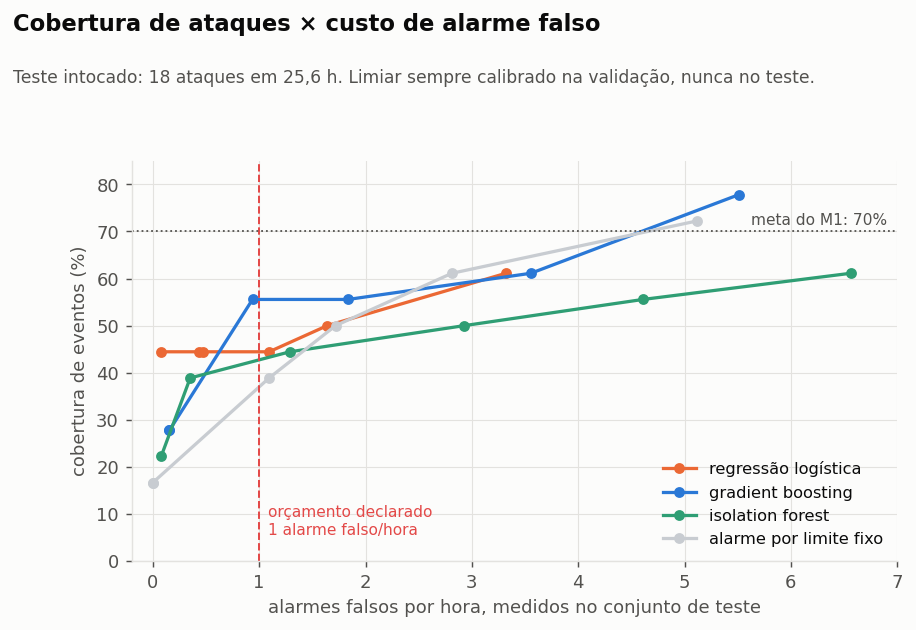

In [15]:
ORCAMENTOS = [0.25, 0.5, 1.0, 2.0, 4.0, 8.0]
curva = []
for nome in ['logistica', 'boosting', 'iforest', 'limite_fixo']:
    s_va, s_te = escores[nome]
    for o in ORCAMENTOS:
        lim = av.calibrar_limiar(s_va, J['ini'][J['va']], y_np, CORTE_TREINO, CORTE_TESTE, 60,
                                 orcamento_hora=o, orcamento_tempo=0.02 * o, n_grade=120)
        flag = av.janelas_para_segundos(J['ini'][J['te']], s_te >= lim, 60, N_SEG)
        curva.append({'modelo': nome, 'orcamento': o, **av.metricas_evento(flag, y_np, CORTE_TESTE, N_SEG)})
curva = pd.DataFrame(curva)

fig, ax = plt.subplots(figsize=(7.6, 4.0))
for nome in ['logistica', 'boosting', 'iforest', 'limite_fixo']:
    d = curva[curva.modelo == nome].sort_values('falsos_por_hora')
    ax.plot(d.falsos_por_hora, d.cobertura * 100, 'o-', color=CORES[nome], lw=1.8, ms=5, label=NOMES[nome])
ax.axvline(1.0, color=S8, ls='--', lw=1.1)
ax.text(1.08, 5, 'orçamento declarado\n1 alarme falso/hora', fontsize=8.5, color=S8, va='bottom')
ax.axhline(70, color=TXT2, ls=':', lw=1)
ax.text(6.9, 71.5, 'meta do M1: 70%', fontsize=8.5, color=TXT2, ha='right')
ax.set_xlabel('alarmes falsos por hora, medidos no conjunto de teste')
ax.set_ylabel('cobertura de eventos (%)'); ax.set_ylim(0, 85); ax.set_xlim(-.2, 7)
ax.legend(fontsize=9, loc='lower right')
titulo(fig, 'Cobertura de ataques × custo de alarme falso',
       'Teste intocado: 18 ataques em 25,6 h. Limiar sempre calibrado na validação, nunca no teste.')
fig.savefig(FIGS / 'g1_curva.png', bbox_inches='tight'); plt.show()

**A meta de 70% declarada na ficha do M1 não foi atingida dentro do orçamento.** No orçamento
de 1 alarme falso/hora a cobertura é de 44%; para chegar a 70% seria preciso aceitar cerca de 5
alarmes falsos por hora e um quarto do tempo normal sob alarme — o que, numa sala de controle,
significa um detector desligado na primeira semana. Registrar isso é parte do trabalho: a meta foi
definida antes de existir qualquer medição. A seção 4 mostra que a meta **é** atingida para a
classe de ataque que os dados conseguem enxergar.

---

## 4. Análise de erros

### 4.1 Quais ataques escapam

O manual técnico do HAI 23.05 traz a tabela dos 52 ataques, com cenário, controlador e pontos
alvo. Os 18 ataques do meu trecho de teste são exatamente os de nº 35 a 52 — **A221 a A238**.
Essa tabela está versionada em `data/externo/ataques_teste.csv`, e com ela dá para perguntar não
*quantos* ataques escapam, mas **quais**.

A tabela separa duas classes, definidas pelo próprio manual:

- **ponto de E/S**: o atacante manipula setpoint, variável de processo ou comando de atuador —
  pontos que **existem** entre as 86 tags;
- **ponto interno**: o atacante altera um parâmetro do **algoritmo** do controlador (curva de
  calibração, valor de inicialização, limiar de monitoração). Esses pontos **não existem** nas
  tags — a classe foi introduzida justamente nesta versão 23.05.

In [16]:
ataques = pd.read_csv(RAIZ / 'data' / 'externo' / 'ataques_teste.csv')
eventos_teste = [(a, b) for a, b in av.eventos(y_np) if a >= CORTE_TESTE]
assert len(eventos_teste) == len(ataques)

MOSTRA = ['limite_fixo', 'iforest', 'boosting', 'logistica']
for nome in MOSTRA:
    fl = resultado[nome]['flag']
    ataques[f'det_{nome}'] = [int(np.flatnonzero(fl[a:b + 1]).size > 0) for a, b in eventos_teste]

por_classe = pd.DataFrame({
    NOMES[n]: ataques.groupby('classe')[f'det_{n}'].apply(lambda s: f'{s.sum()}/{len(s)} ({s.mean()*100:.0f}%)')
    for n in MOSTRA})
por_classe.index = ['ponto interno', 'ponto de E/S']
por_classe.T

,ponto interno,ponto de E/S
alarme por limite fixo,0/7 (0%),7/11 (64%)
isolation forest,0/7 (0%),8/11 (73%)
gradient boosting,1/7 (14%),9/11 (82%)
regressão logística,0/7 (0%),8/11 (73%)


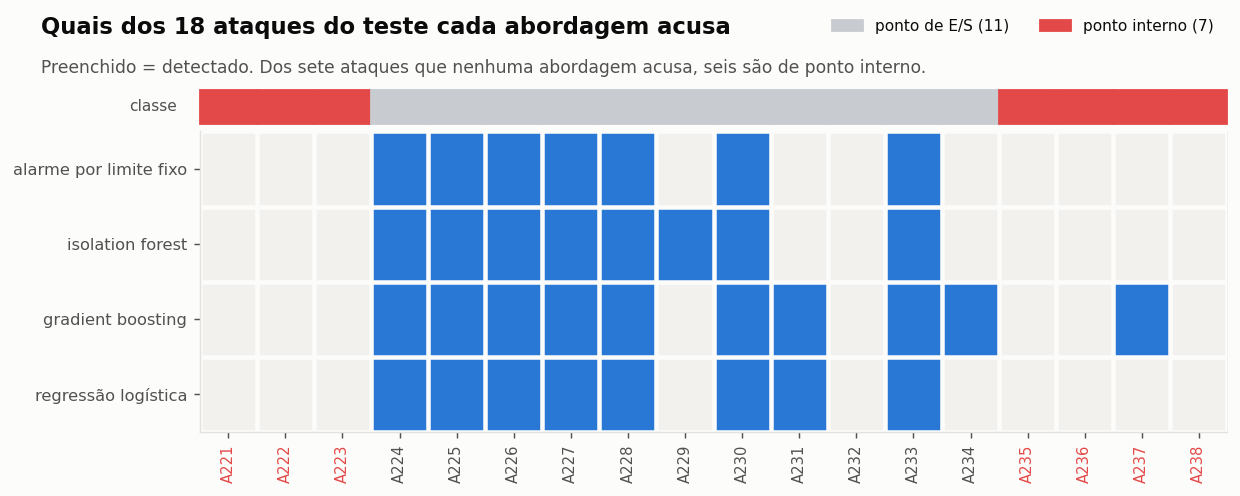

In [17]:
mods = MOSTRA
M = ataques[[f'det_{m}' for m in mods]].to_numpy().T
fig, ax = plt.subplots(figsize=(10.2, 3.0))
ax.imshow(M, cmap=matplotlib.colors.ListedColormap(['#f2f1ee', S1]), aspect='auto', vmin=0, vmax=1)
ax.set_xticks(np.arange(-.5, len(ataques), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(mods), 1), minor=True)
ax.grid(which='minor', color=SURF, lw=2.5); ax.grid(which='major', visible=False)
ax.tick_params(which='minor', length=0)
ax.set_xticks(range(len(ataques))); ax.set_xticklabels(ataques.id, fontsize=8.2, rotation=90)
for jj, c in enumerate(ataques.classe):
    ax.get_xticklabels()[jj].set_color(S8 if c == 'interno' else TXT2)
    ax.add_patch(plt.Rectangle((jj - .5, -1.05), 1, .45, color=S8 if c == 'interno' else NEU, clip_on=False))
ax.set_yticks(range(len(mods))); ax.set_yticklabels([NOMES[m] for m in mods], fontsize=9)
ax.text(-.9, -.83, 'classe', ha='right', va='center', fontsize=8.5, color=TXT2)
ax.legend(handles=[Patch(color=NEU, label='ponto de E/S (11)'), Patch(color=S8, label='ponto interno (7)')],
          fontsize=8.5, ncol=2, loc='upper right', bbox_to_anchor=(1.0, 1.42))
titulo(fig, 'Quais dos 18 ataques do teste cada abordagem acusa',
       'Preenchido = detectado. Dos sete ataques que nenhuma abordagem acusa, seis são de ponto interno.')
fig.savefig(FIGS / 'g3_mapa.png', bbox_inches='tight'); plt.show()

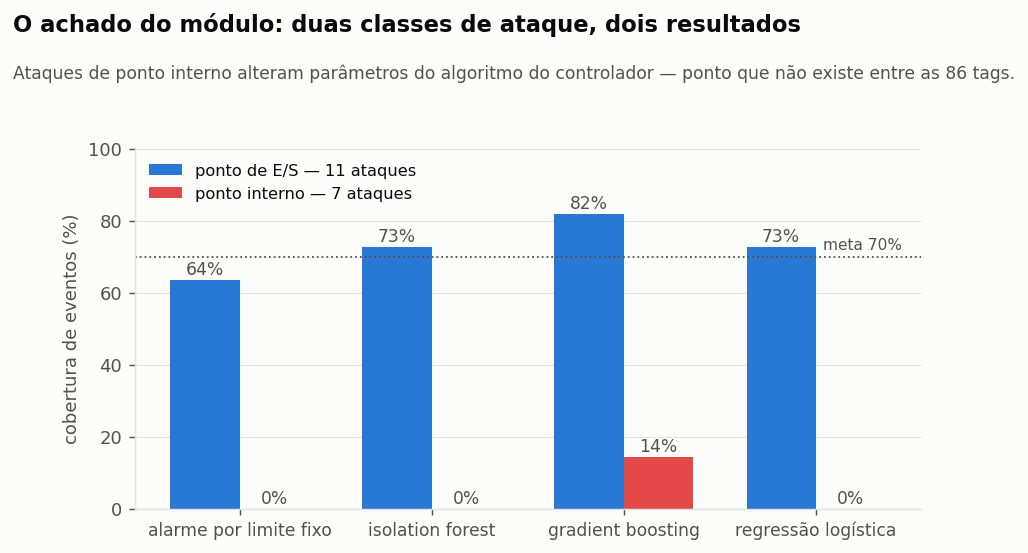

In [18]:
fig, ax = plt.subplots(figsize=(7.8, 3.6))
x = np.arange(len(mods)); w = .36
io_ = [ataques[ataques.classe == 'io'][f'det_{m}'].mean() * 100 for m in mods]
it_ = [ataques[ataques.classe == 'interno'][f'det_{m}'].mean() * 100 for m in mods]
b1 = ax.bar(x - w/2, io_, w, color=S1, label='ponto de E/S — 11 ataques')
b2 = ax.bar(x + w/2, it_, w, color=S8, label='ponto interno — 7 ataques')
for bars, v in ((b1, io_), (b2, it_)):
    for bb, vv in zip(bars, v):
        ax.text(bb.get_x() + bb.get_width()/2, vv + 1.5, f'{vv:.0f}%', ha='center', fontsize=9.5, color=TXT2)
ax.axhline(70, color=TXT2, ls=':', lw=1); ax.text(3.45, 72, 'meta 70%', fontsize=8.5, color=TXT2, ha='right')
ax.set_xticks(x); ax.set_xticklabels([NOMES[m] for m in mods], fontsize=9.5)
ax.set_ylabel('cobertura de eventos (%)'); ax.set_ylim(0, 100)
ax.grid(axis='x', visible=False); ax.set_axisbelow(True); ax.legend(fontsize=9, loc='upper left')
titulo(fig, 'O achado do módulo: duas classes de ataque, dois resultados',
       'Ataques de ponto interno alteram parâmetros do algoritmo do controlador — ponto que não existe entre as 86 tags.')
fig.savefig(FIGS / 'g2_classe.png', bbox_inches='tight'); plt.show()

**Este é o resultado central do módulo.** O erro do detector não está espalhado: ele está
concentrado em uma classe inteira de ataque.

- **Ponto de E/S: 8 de 11 (73%)** com a regressão logística — a meta de 70% é atingida nessa classe.
- **Ponto interno: 0 de 7 (0%)** — nenhuma das quatro abordagens acusa um só, com uma única exceção
  (o gradient boosting pega o A237).

A explicação não é estatística, é de instrumentação. Um ataque de ponto interno muda, por exemplo,
o valor de inicialização de uma função de E/S artificial de 40 para 12, ou o máximo de uma curva de
calibração de 100 para 90. O ponto manipulado é **interno ao algoritmo do controlador** e nunca
aparece no historiador SCADA. O efeito no processo é lento e fica dentro da faixa operacional.
**Nenhum modelo sobre essas 86 tags vai detectar isso** — é limitação dos dados, não do algoritmo.

A leitura operacional é direta, e é a recomendação que levo deste módulo: detectar essa classe
exige visibilidade do **programa do controlador** — monitorar alteração de lógica e de parâmetros
na estação de engenharia —, não mais modelos sobre o historiador.

Não é a duração que separa detectados de escapados: a mediana é 125 s entre os detectados e 121 s
entre os que escapam. É a classe.

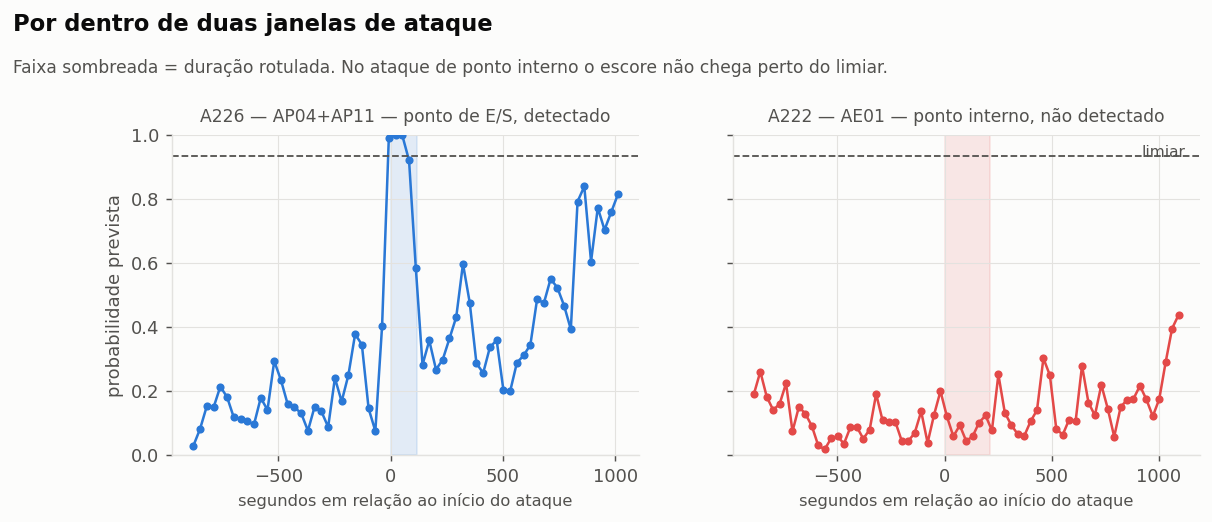

In [19]:
casos = [('A226', 'AP04+AP11 — ponto de E/S, detectado', S1),
         ('A222', 'AE01 — ponto interno, não detectado', S8)]
it_ini = J['ini'][J['te']]
fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.2), sharey=True)
for ax, (idd, sub, cor) in zip(axes, casos):
    linha = ataques[ataques.id == idd].iloc[0]
    k = list(ataques.id).index(idd)
    a, dur = eventos_teste[k][0], int(linha.duracao_s)
    m = (it_ini >= a - 900) & (it_ini <= a + dur + 900)
    ax.plot(it_ini[m] - a, s_te_final[m], 'o-', color=cor, ms=3.5, lw=1.4)
    ax.axhline(limiar['logistica'], color=TXT2, ls='--', lw=1)
    ax.axvspan(0, dur, color=cor, alpha=.12)
    ax.set_xlabel('segundos em relação ao início do ataque', fontsize=9)
    ax.text(.5, 1.04, f'{idd} — {sub}', transform=ax.transAxes, ha='center', fontsize=9.5, color=TXT2)
axes[0].set_ylabel('probabilidade prevista'); axes[0].set_ylim(0, 1)
axes[1].text(.97, .93, 'limiar', transform=axes[1].transAxes, ha='right', fontsize=8.5, color=TXT2)
titulo(fig, 'Por dentro de duas janelas de ataque',
       'Faixa sombreada = duração rotulada. No ataque de ponto interno o escore não chega perto do limiar.')
fig.savefig(FIGS / 'g6_series.png', bbox_inches='tight'); plt.show()

### 4.2 O que o modelo usa — e o que ele não usa

Importância por permutação: quanto o PR-AUC cai ao embaralhar cada feature.

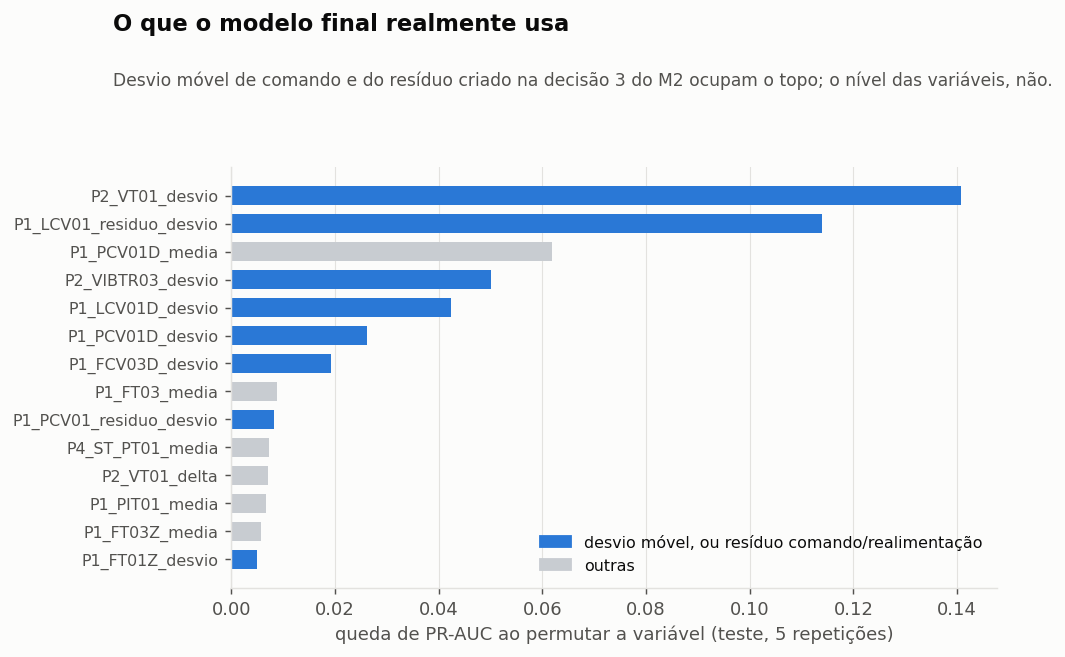

In [20]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final, J['X'][J['te']], J['y'][J['te']], n_repeats=5,
                            random_state=SEMENTE, scoring='average_precision', n_jobs=2)
imp = pd.Series(pi.importances_mean, index=J['X'].columns).sort_values(ascending=False)

top = imp.head(14)[::-1]
fig, ax = plt.subplots(figsize=(7.6, 4.2))
cor = [S1 if ('_residuo' in i or i.endswith('_desvio')) else NEU for i in top.index]
ax.barh(range(len(top)), top.values, color=cor, height=.68)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index, fontsize=8.8)
ax.set_xlabel('queda de PR-AUC ao permutar a variável (teste, 5 repetições)')
ax.grid(axis='y', visible=False); ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=S1, label='desvio móvel, ou resíduo comando/realimentação'),
                   Patch(color=NEU, label='outras')], fontsize=8.8, loc='lower right')
titulo(fig, 'O que o modelo final realmente usa',
       'Desvio móvel de comando e do resíduo criado na decisão 3 do M2 ocupam o topo; o nível das variáveis, não.')
fig.savefig(FIGS / 'g5_importancia.png', bbox_inches='tight'); plt.show()

In [21]:
flags_m2 = [c for c in J['X'].columns if 'fora_repouso' in c]
pd.DataFrame({'importância': imp[flags_m2].round(5),
              'posição entre as 192': [list(imp.index).index(c) + 1 for c in flags_m2]})

,importância,posição entre as 192
P1_PCV02D_fora_repouso_media,0.00016,72
P1_PCV02D_fora_repouso_desvio,-0.00022,142
P1_PCV02D_fora_repouso_delta,0.00010,80


**Duas leituras, uma a favor e uma contra decisões do M2.**

**A favor da decisão 3.** O topo da lista é ocupado por **desvios móveis de comando de atuador** e
pelo **desvio do resíduo comando/realimentação** — variáveis que só existem porque, no M2, optei por
substituir cada par comando/realimentação pela **diferença** em vez de descartar o lado menos
interpretável, como a regra geral mandaria. Se eu tivesse seguido a regra, essas variáveis não
existiriam. A escolha foi um desvio consciente e documentado; o modelo mostra que ela valeu.

**Contra a flag de repouso.** No M2, `P1_PCV02D` sair do valor de repouso 94× mais sob ataque
(6,89% × 0,07%) foi o achado mais chamativo da EDA. No modelo final as três features derivadas dela
têm importância **praticamente nula** (posições 72, 80 e 142 de 192). O sinal que ela carrega já está
contido no desvio móvel dos comandos, que o modelo prefere. Achado univariado forte não é feature
útil — registro isso como erro de expectativa meu, não como resultado a esconder.

**Um alerta honesto sobre a divergência entre critério e resultado.** A seleção feita dentro do
treino escolheu a regressão logística; no teste, o gradient boosting cobriu 10 eventos contra 8.
Eu **não** troquei o modelo por causa disso — fazer isso seria ajustar no teste, exatamente a
armadilha que a disciplina nomeia. Com 18 eventos, dois eventos de diferença estão dentro da
variação amostral; e o boosting só chega lá gastando 3,3% do tempo normal em alarme contra 1,9%
da logística. Registro a divergência como resultado, não como motivo para refazer a escolha.

---

## 5. Limitações

**Dos dados.**

1. **Testbed, não planta real.** O HAI é um simulador HIL de uma turbina e caldeira. Os números
   aqui não transferem para outra instalação sem recalibração.
2. **A classe de ponto interno é invisível nestes dados.** Sete dos 18 ataques do teste manipulam
   parâmetros internos do algoritmo do controlador, que não estão entre as 86 tags. Nenhum modelo
   sobre esse conjunto resolve — e nenhum resultado sobre essa classe deve ser prometido.
3. **18 eventos no teste.** Um evento a mais ou a menos move a cobertura em 5,6 pontos. Por isso
   reporto a curva cobertura × alarme inteira, e não um número único.
4. **Rótulos por subprocesso foram removidos a partir da versão 22.04.** O escopo é detecção, sem
   localização de qual subprocesso foi atacado.

**Das condições de treino.**

5. **O modelo aprendeu com 40 h e 33 eventos.** Regimes de operação não representados nesse trecho
   vão gerar alarme falso. O orçamento de alarme é calibrado em 13,4 h de validação — uma janela
   curta para estimar uma taxa de alarme falso com precisão, e provavelmente é por isso que no teste
   as abordagens não supervisionadas estouraram o orçamento calibrado.
6. **O limiar é fixo.** Em operação, ele precisaria ser recalibrado periodicamente, porque a
   definição de "normal" da planta muda com manutenção, estação do ano e mudança de produto.
7. **Rótulos perfeitos.** Em produção não existe o rótulo que diz onde o ataque começou; a avaliação
   por evento depende dele. O que se consegue medir em campo é a taxa de alarme falso.
8. **Latência medida em dados de 1 Hz, offline.** Não inclui o tempo de coleta, transporte e
   apresentação do alarme num ambiente real.

**Do método.**

9. `TimeSeriesSplit` no lugar de `StratifiedKFold` é uma divergência deliberada do checklist da
   disciplina, justificada na seção 2.1. Ela torna os números **menos** otimistas, não mais.
10. A seleção fora-da-amostra usa 14 eventos. É pouco. É, ainda assim, mais do que escolher pelo
    teste.

---

## Síntese

| | |
|---|---|
| **Modelo final** | regressão logística, `class_weight='balanced'`, janela de 60 s, `StandardScaler` no `Pipeline` |
| **Escolhido por** | cobertura fora-da-amostra dentro do treino (57%, 0,24 alarme falso/h), confirmada por F1 e PR-AUC em CV |
| **Cobertura no teste** | **8 de 18 ataques (44%)** a 0,43 alarme falso/hora e 1,9% do tempo normal em alarme |
| **Por classe de ataque** | **ponto de E/S: 8 de 11 (73%)** · ponto interno: 0 de 7 |
| **Latência mediana** | 0 s — quando detecta, detecta na primeira janela |
| **Piso que isso supera** | resíduo com limiar p99 (M1): 1 de 14 eventos · baseline trivial: 0 |
| **Meta do M1 (70%)** | não atingida no total; **atingida na classe que os dados enxergam** |

O que eu levo deste módulo não é o modelo. É que o modelo mais simples ganhou do mais complexo,
que a decisão de pré-processamento mais arriscada do M2 foi a que mais rendeu, que o achado mais
bonito da EDA não serviu para nada — e que metade do problema não está no algoritmo, está em
**qual ponto a planta instrumenta**.

---

## Declaração de uso de Inteligência Artificial

Conforme a política da disciplina. Usei assistente de IA **Claude (Anthropic)** como ferramenta 
de apoio: discussão de alternativas de modelagem, revisão de código e redação. **As decisões de escopo, 
de pré-processamento, de métrica, de corte temporal, de critério de seleção e de modelo final 
são minhas**, tomadas após avaliar as alternativas registradas neste caderno e em `prompts_log.md`, 
na raiz do repositório, onde está o diário de uso.